In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds

from tensorflow.keras.utils import to_categorical
print("TensorFlow:", tf.__version__)

TensorFlow: 2.20.0


In [2]:
import os
import tensorflow as tf
import numpy as np

dataset_path = os.path.expanduser("~/flower_photos")

train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    image_size=(150, 150),
    batch_size=16,
    validation_split=0.3,
    subset="training",
    seed=42
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    image_size=(150, 150),
    batch_size=16,
    validation_split=0.3,
    subset="validation",
    seed=42
)

print("Training dataset loaded successfully!")
print("Flower classes:", train_ds.class_names)

FileNotFoundError: [WinError 3] The system cannot find the path specified: 'C:\\Users\\Dell/flower_photos'

In [15]:
from tensorflow.keras.applications import VGG16

base_model = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(150, 150, 3)
)

base_model.summary()

Model: "vgg16"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_3 (InputLayer)        [(None, 150, 150, 3)]     0         
                                                                 
 block1_conv1 (Conv2D)       (None, 150, 150, 64)      1792      
                                                                 
 block1_conv2 (Conv2D)       (None, 150, 150, 64)      36928     
                                                                 
 block1_pool (MaxPooling2D)  (None, 75, 75, 64)        0         
                                                                 
 block2_conv1 (Conv2D)       (None, 75, 75, 128)       73856     
                                                                 
 block2_conv2 (Conv2D)       (None, 75, 75, 128)       147584    
                                                                 
 block2_pool (MaxPooling2D)  (None, 37, 37, 128)       0     

In [16]:
base_model.trainable = False

print("VGG16 layers frozen successfully!")
print("Base model trainable:", base_model.trainable)

VGG16 layers frozen successfully!
Base model trainable: False


In [17]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications.vgg16 import preprocess_input

model = models.Sequential([
    layers.Input(shape=(150, 150, 3)),

    layers.Lambda(preprocess_input),

    base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),

    layers.Dropout(0.3),

    layers.Dense(5, activation="softmax")
])

model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lambda_1 (Lambda)           (None, 150, 150, 3)       0         
                                                                 
 vgg16 (Functional)          (None, 4, 4, 512)         14714688  
                                                                 
 global_average_pooling2d_1  (None, 512)               0         
  (GlobalAveragePooling2D)                                       
                                                                 
 dense_2 (Dense)             (None, 128)               65664     
                                                                 
 dropout_1 (Dropout)         (None, 128)               0         
                                                                 
 dense_3 (Dense)             (None, 5)                 645       
                                                      

In [18]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [19]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=2,
    callbacks=[early_stop]
)

Epoch 1/2
161/161 [==============================] - 210s 1s/step - loss: 2.0860 - accuracy: 0.6458 - val_loss: 0.7663 - val_accuracy: 0.7702
Epoch 2/2
161/161 [==============================] - 205s 1s/step - loss: 0.5895 - accuracy: 0.8116 - val_loss: 0.6953 - val_accuracy: 0.7920


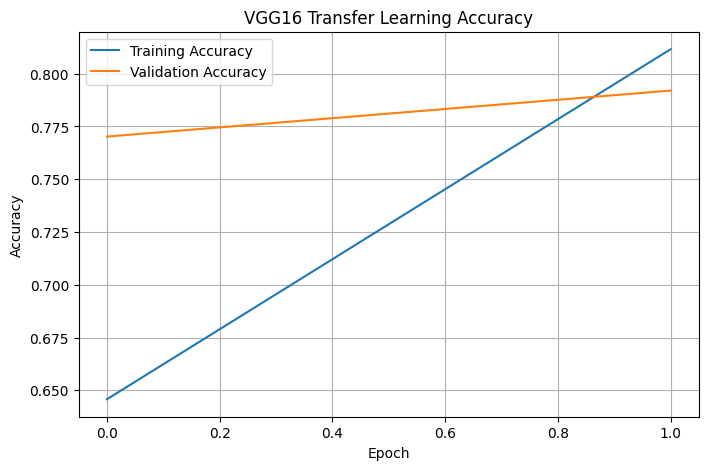

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
 +
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("VGG16 Transfer Learning Accuracy")
plt.legend()
plt.grid(True)

plt.show()

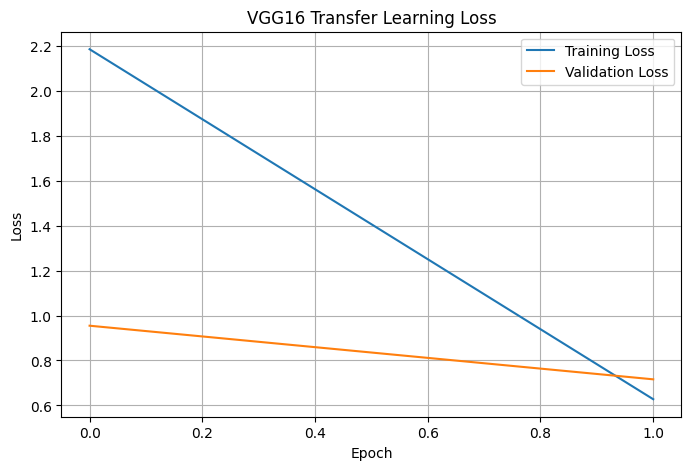

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VGG16 Transfer Learning Loss")
plt.legend()
plt.grid(True)

plt.show()

1/1 [==============================] - 1s 1s/step


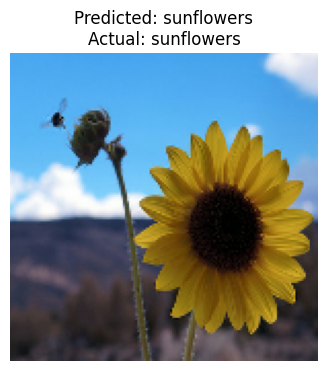

Predicted flower: sunflowers
Actual flower: sunflowers
Confidence: 97.32 %
----------------------------------------


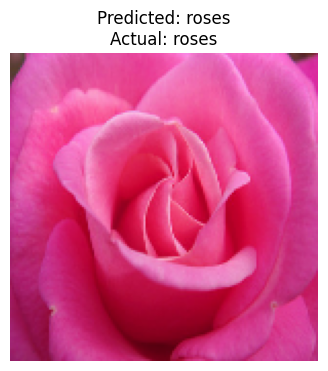

Predicted flower: roses
Actual flower: roses
Confidence: 98.52 %
----------------------------------------


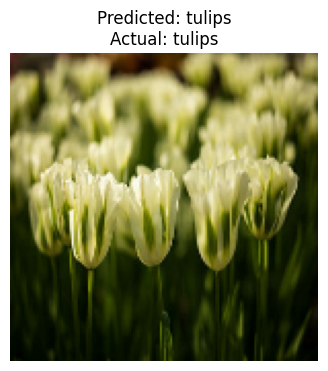

Predicted flower: tulips
Actual flower: tulips
Confidence: 97.44 %
----------------------------------------


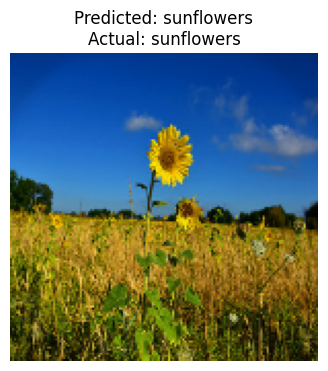

Predicted flower: sunflowers
Actual flower: sunflowers
Confidence: 86.76 %
----------------------------------------


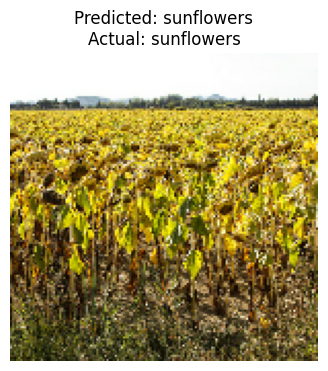

Predicted flower: sunflowers
Actual flower: sunflowers
Confidence: 86.68 %
----------------------------------------


In [11]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

class_names = train_ds.class_names

for images, labels in test_ds.take(1):

    predictions = model.predict(images)

    for i in range(5):
        predicted_label = np.argmax(predictions[i])
        actual_label = labels[i].numpy()

        plt.figure(figsize=(4, 4))
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(
            f"Predicted: {class_names[predicted_label]}\n"
            f"Actual: {class_names[actual_label]}"
        )
        plt.axis("off")
        plt.show()

        print("Predicted flower:", class_names[predicted_label])
        print("Actual flower:", class_names[actual_label])
        print("Confidence:", round(float(np.max(predictions[i])) * 100, 2), "%")
        print("-" * 40)